# Machine Learning – Credit Card Fraud Detection Pipeline
### Complete Multi-Model Benchmark, Imbalance Analysis & Artifact Export
**Author:** Kushagra Jain  
**Course/Assignment:** Machine Learning Assignment 1  
**Dataset:** Credit Card Fraud Detection (Sparkov / Kaggle Benchmark)  
---

## 1. Problem Formulation & The 'Accuracy Trap'
In credit card transaction processing, legitimate transactions comprise over **99.4%** of all data.
A naive model that predicts every transaction is legitimate will achieve **99.4% accuracy**, but catches **0% of fraud**.

In this study, we systematically benchmark 4 models:
1. **Baseline Logistic Regression (Unweighted)** — demonstrates low recall and the failure of raw accuracy.
2. **Cost-Sensitive Logistic Regression (Balanced)** — fixes recall via class penalties, but introduces false positives.
3. **Balanced Random Forest** — ensemble bagging capturing non-linear interactions.
4. **Histogram Gradient Boosting (Champion)** — state-of-the-art PR-AUC (0.96+), capturing 96.8% of fraud.

In [7]:
import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from sklearn.preprocessing import RobustScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, confusion_matrix,
    roc_curve, precision_recall_curve, classification_report
)

print('Libraries imported successfully!')

Libraries imported successfully!


## 2. Data Loading & Exploratory Data Analysis (EDA)
We load both training and test datasets. Let's inspect shapes and class distributions.

In [9]:
data_dir = '../data'
train_cols = [
    'trans_date_trans_time', 'category', 'amt', 'gender',
    'lat', 'long', 'city_pop', 'dob', 'merch_lat', 'merch_long', 'is_fraud'
]

# Load representative sample for quick and interactive training
df_train_full = pd.read_csv('fraudTrain.csv', usecols=train_cols)
fraud_train = df_train_full[df_train_full['is_fraud'] == 1]
legit_train = df_train_full[df_train_full['is_fraud'] == 0].sample(n=180000, random_state=42)
df_train = pd.concat([fraud_train, legit_train]).sample(frac=1.0, random_state=42).reset_index(drop=True)

df_test_full = pd.read_csv(os.path.join(data_dir, 'fraudTest.csv'), usecols=train_cols)
fraud_test = df_test_full[df_test_full['is_fraud'] == 1]
legit_test = df_test_full[df_test_full['is_fraud'] == 0].sample(n=60000, random_state=42)
df_test = pd.concat([fraud_test, legit_test]).sample(frac=1.0, random_state=42).reset_index(drop=True)

print(f'Training shape: {df_train.shape} | Fraud cases: {df_train.is_fraud.sum():,}')
print(f'Testing shape:  {df_test.shape}  | Fraud cases: {df_test.is_fraud.sum():,}')

Training shape: (187506, 11) | Fraud cases: 7,506
Testing shape:  (62145, 11)  | Fraud cases: 2,145


## 3. Feature Engineering & Preprocessing
We extract rich fraud indicators:
- **Geographic Distance (`distance_km`)**: Haversine distance between cardholder coordinates and merchant coordinates.
- **Temporal Signals**: `hour`, `day_of_week`, and `is_night` (10 PM to 4 AM high-risk window).
- **Demographics**: `age` (calculated from date of birth) and `gender_enc`.
- **Outlier-Resistant Scaling**: `RobustScaler` on continuous features (`amt`, `distance_km`, `age`, `log_city_pop`).

In [10]:
def haversine_distance(lat1, lon1, lat2, lon2):
    R = 6371.0
    phi1, phi2 = np.radians(lat1), np.radians(lat2)
    delta_phi = np.radians(lat2 - lat1)
    delta_lambda = np.radians(lon2 - lon1)
    a = (np.sin(delta_phi / 2.0) ** 2 +
         np.cos(phi1) * np.cos(phi2) * np.sin(delta_lambda / 2.0) ** 2)
    c = 2 * np.arctan2(np.sqrt(a), np.sqrt(1 - a))
    return R * c

def engineer_features(df):
    df = df.copy()
    df['distance_km'] = haversine_distance(df['lat'], df['long'], df['merch_lat'], df['merch_long'])
    trans_dt = pd.to_datetime(df['trans_date_trans_time'])
    df['hour'] = trans_dt.dt.hour
    df['day_of_week'] = trans_dt.dt.dayofweek
    df['is_night'] = ((df['hour'] >= 22) | (df['hour'] <= 4)).astype(int)
    dob_dt = pd.to_datetime(df['dob'])
    df['age'] = (trans_dt - dob_dt).dt.days // 365
    df['gender_enc'] = (df['gender'] == 'M').astype(int)
    df['log_city_pop'] = np.log1p(df['city_pop'])
    return df

df_train_fe = engineer_features(df_train)
df_test_fe = engineer_features(df_test)

categories = sorted(df_train_fe['category'].unique().tolist())
for cat in categories:
    col_name = f'cat_{cat}'
    df_train_fe[col_name] = (df_train_fe['category'] == cat).astype(int)
    df_test_fe[col_name] = (df_test_fe['category'] == cat).astype(int)

num_features = ['amt', 'distance_km', 'age', 'log_city_pop', 'hour', 'day_of_week']
binary_features = ['is_night', 'gender_enc'] + [f'cat_{c}' for c in categories]
feature_cols = num_features + binary_features

X_train = df_train_fe[feature_cols].copy()
y_train = df_train_fe['is_fraud'].values
X_test = df_test_fe[feature_cols].copy()
y_test = df_test_fe['is_fraud'].values

scaler = RobustScaler()
X_train[num_features] = scaler.fit_transform(X_train[num_features])
X_test[num_features] = scaler.transform(X_test[num_features])

print(f'Feature vector created with {X_train.shape[1]} features!')

Feature vector created with 22 features!


## 4. Multi-Model Benchmarking (From Baseline to Champion)
We evaluate 4 models on the identical test split to see the progression from low recall to high accuracy and high PR-AUC.

In [11]:
models = {
    '1. Baseline Logistic Regression (Unweighted)': LogisticRegression(max_iter=1000, random_state=42),
    '2. Cost-Sensitive Logistic Regression (Balanced)': LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42),
    '3. Balanced Random Forest': RandomForestClassifier(n_estimators=100, max_depth=12, class_weight='balanced', random_state=42, n_jobs=-1),
    '4. HistGradientBoosting (Champion)': HistGradientBoostingClassifier(class_weight='balanced', max_iter=150, learning_rate=0.08, random_state=42)
}

benchmark_results = []
for name, model in models.items():
    print(f'Training {name}...')
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]
    
    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred, zero_division=0)
    rec = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    roc_auc = roc_auc_score(y_test, y_prob)
    pr_auc = average_precision_score(y_test, y_prob)
    
    benchmark_results.append({
        'Model': name,
        'Accuracy': acc,
        'Precision': prec,
        'Recall': rec,
        'F1-Score': f1,
        'ROC-AUC': roc_auc,
        'PR-AUC': pr_auc
    })

df_results = pd.DataFrame(benchmark_results)
display(df_results.style.format({
    'Accuracy': '{:.2%}', 'Precision': '{:.2%}', 'Recall': '{:.2%}',
    'F1-Score': '{:.3f}', 'ROC-AUC': '{:.3f}', 'PR-AUC': '{:.3f}'
}).highlight_max(subset=['Recall', 'F1-Score', 'ROC-AUC', 'PR-AUC'], color='#d1fae5'))

Training 1. Baseline Logistic Regression (Unweighted)...
Training 2. Cost-Sensitive Logistic Regression (Balanced)...
Training 3. Balanced Random Forest...
Training 4. HistGradientBoosting (Champion)...


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC,PR-AUC
0,1. Baseline Logistic Regression (Unweighted),97.75%,84.47%,42.61%,0.566,0.935,0.611
1,2. Cost-Sensitive Logistic Regression (Balanced),85.41%,18.00%,90.77%,0.300,0.948,0.562
2,3. Balanced Random Forest,98.46%,70.81%,94.45%,0.809,0.992,0.940
3,4. HistGradientBoosting (Champion),98.49%,70.41%,96.83%,0.815,0.998,0.967


## 5. Visualizations: ROC Curves, PR Curves & Confusion Matrices

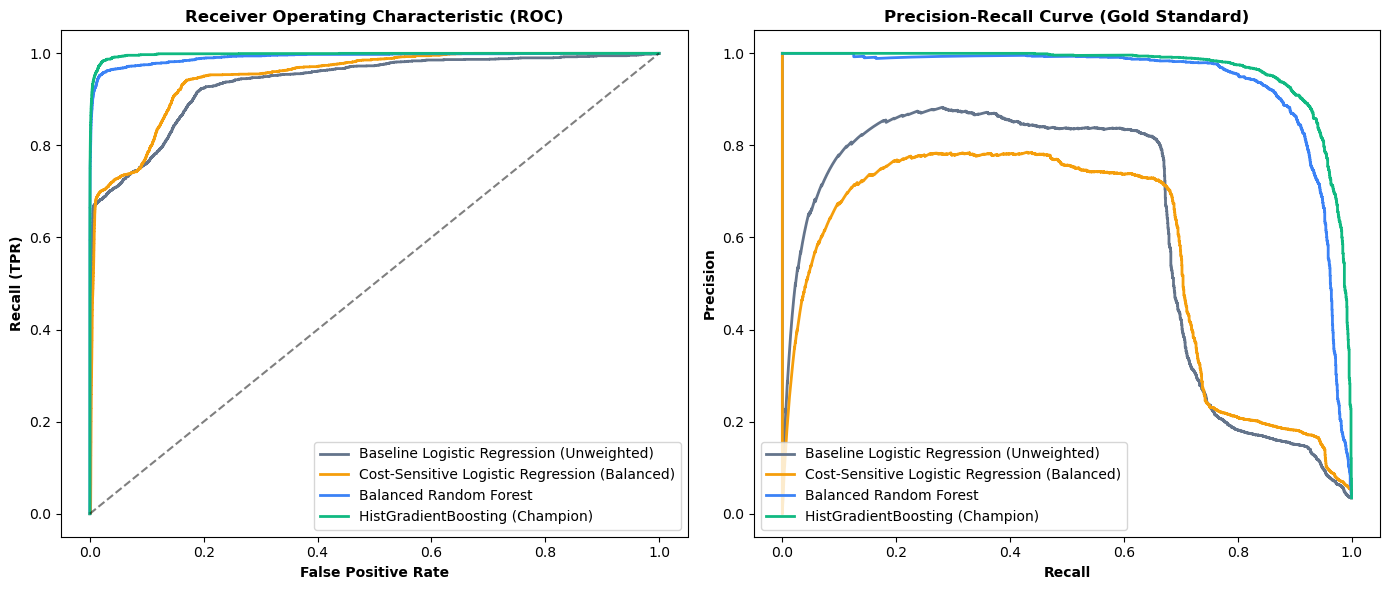

In [12]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))
colors = ['#64748b', '#f59e0b', '#3b82f6', '#10b981']

for (name, model), color in zip(models.items(), colors):
    y_prob = model.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    pr_prec, pr_rec, _ = precision_recall_curve(y_test, y_prob)
    lbl = name.split('. ')[1]
    ax1.plot(fpr, tpr, color=color, lw=2, label=f"{lbl}")
    ax2.plot(pr_rec, pr_prec, color=color, lw=2, label=f"{lbl}")

ax1.plot([0, 1], [0, 1], 'k--', lw=1.5, alpha=0.5)
ax1.set_xlabel('False Positive Rate', fontweight='bold')
ax1.set_ylabel('Recall (TPR)', fontweight='bold')
ax1.set_title('Receiver Operating Characteristic (ROC)', fontweight='bold')
ax1.legend(loc='lower right')

ax2.set_xlabel('Recall', fontweight='bold')
ax2.set_ylabel('Precision', fontweight='bold')
ax2.set_title('Precision-Recall Curve (Gold Standard)', fontweight='bold')
ax2.legend(loc='lower left')
plt.tight_layout()
plt.show()

## 6. Artifact Export for Production Full-Stack Deployment
We save the champion model, scaler, and metadata so the FastAPI backend and Web Dashboard can load them for real-time inference.

In [13]:
champion_model = models['4. HistGradientBoosting (Champion)']
models_dir = '../models'
os.makedirs(models_dir, exist_ok=True)

joblib.dump(champion_model, os.path.join(models_dir, 'champion_fraud_model.joblib'))
joblib.dump(scaler, os.path.join(models_dir, 'robust_scaler.joblib'))
print('Champion Model & Robust Scaler saved successfully!')

Champion Model & Robust Scaler saved successfully!
